In [1]:
! pip install tensorflow
import tensorflow as tf
 

# Load = "MNIST DATA Set"
Contraining Training sample =60,000, Testing sample =10,000
tensorflow already contain MNIST data set which can be loaded useing keras
 


In [2]:
mnist = tf.keras.datasets.mnist

After loading the MNIST data, divide into train  and test datasets

In [3]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train.shape

(60000, 28, 28)

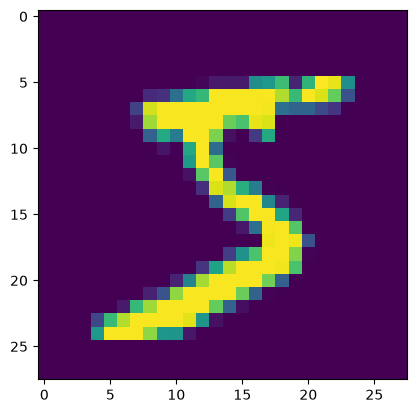

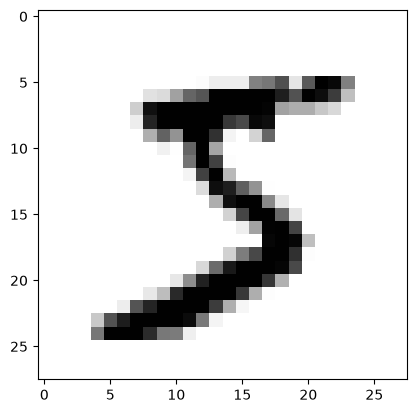

In [4]:
## just check the graphical how the data looks like
! pip install matplotlib
import matplotlib.pyplot as plt
plt.imshow(X_train[0]) 
plt.show() 
plt.imshow(X_train[0], cmap = plt.cm.binary)

## Checking  the values of each pixel
##before the normalization the values of each pixel is between 0 to 255

In [5]:
print(X_train[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

## as image are in Gray level(1 channel==>0 to255),not coloursed(RGB)
Normalizing the data data preprocessing  step

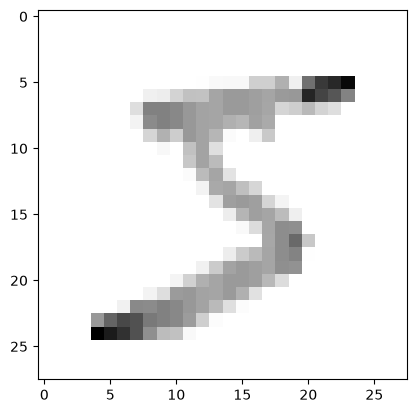

In [6]:
X_train =tf.keras.utils.normalize(X_train, axis = 1)
X_test = tf.keras.utils.normalize(X_test, axis = 1)
plt.imshow(X_train[0], cmap = plt.cm.binary)

After Normalization

In [7]:
print(X_train[0]) ## you can see all values are now normalized between 0 and 1. This is important for the model to learn better.

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.    

In [8]:
print(y_train[0])

5


## Resting  img to make it suitable  for apply convluation operation

In [9]:
! pip install numpy
import numpy as np
IMAGE_SIZE = 28
X_train = np.array(X_train).reshape(-1, IMAGE_SIZE, IMAGE_SIZE, 1)
X_test = np.array(X_test).reshape(-1, IMAGE_SIZE, IMAGE_SIZE, 1)
print("Training samples dimension: ", X_train.shape)
print("Testing samples dimension: ", X_test.shape)

Training samples dimension:  (60000, 28, 28, 1)
Testing samples dimension:  (10000, 28, 28, 1)


## Create Deep Neural Network
Training on 60,000 sample of MNIST handwritten  dataset

In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Flatten, Dense
from tensorflow.keras.layers import Dense, Conv2D, Flatten, MaxPooling2D

In [11]:
## Creating a  neural network model
model = Sequential()

### first convolution layer
model.add(Conv2D(64, (3,3), activation = 'relu', input_shape = X_train.shape[1:]))
model.add(Activation('relu')) ## adding activation function
model.add(MaxPooling2D(pool_size = (2,2))) ## adding max pooling layer

### second convolution layer
model.add(Conv2D(64, (3,3), activation = 'relu'))
model.add(Activation('relu')) ## adding activation function
model.add(MaxPooling2D(pool_size = (2,2))) ## adding max pooling layer

### third convolution layer
model.add(Conv2D(64, (3,3), activation = 'relu'))
model.add(Activation('relu')) ## adding activation function
model.add(MaxPooling2D(pool_size = (2,2))) ## adding max pooling layer

### full connection layer =1
model.add(Flatten()) ## flattening the 3D array to 1D
model.add(Dense(64)) ## adding a dense layer with 64 neurons
model.add(Activation('relu')) ## adding activation function

### full connection layer =2
model.add(Dense(32)) ## adding a dense layer with 32 neurons
model.add(Activation('relu')) ## adding activation function
model.add(Dense(10)) ## adding a dense layer with 10 neurons for 10 classes

### full connection layer =3
model.add(Dense(10)) ## adding a dense layer with 10 neurons for 10 classes
model.add(Activation('softmax')) ## adding activation function for multi-class classification
model.compile(loss = 'sparse_categorical_crossentropy', optimizer = 'adam', metrics = ['accuracy']) ## compiling

c:\Users\DELL\miniconda3\envs\Handwritten_Character_Recongnition\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
model.summary() ## printing the summary of the model

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,176 (317.09 KB)

 Trainable params: 81,176 (317.09 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
print("total Training samples:", len(X_train))


total Training samples: 60000


In [14]:
model.compile(loss = 'sparse_categorical_crossentropy', optimizer = 'adam', metrics = ['accuracy']) ## compiling
model.fit(X_train, y_train,epochs = 5, validation_split = 0.3) ## training the model with 5 epochs and 10% validation

Epoch 1/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 178s 124ms/step - accuracy: 0.8905 - loss: 0.3461 - val_accuracy: 0.9581 - val_loss: 0.1345
Epoch 2/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 263s 170ms/step - accuracy: 0.9665 - loss: 0.1113 - val_accuracy: 0.9683 - val_loss: 0.1009
Epoch 3/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 178s 136ms/step - accuracy: 0.9765 - loss: 0.0785 - val_accuracy: 0.9715 - val_loss: 0.0928
Epoch 4/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 136s 103ms/step - accuracy: 0.9809 - loss: 0.0612 - val_accuracy: 0.9802 - val_loss: 0.0652
Epoch 5/5
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 226s 167ms/step - accuracy: 0.9842 - loss: 0.0509 - val_accuracy: 0.9780 - val_loss: 0.0730


In [15]:
### Evaluating on the testing dataset MNIST
test_Loss , test_Accuracy =model.evaluate(X_test,y_test)
print("Test Loss on 10,000 sample dataset:", test_Loss)
print("validation Accuracy on 10,000 sample dataset:", test_Accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.9792 - loss: 0.0692
Test Loss on 10,000 sample dataset: 0.06922698765993118
validation Accuracy on 10,000 sample dataset: 0.979200005531311


In [16]:
## prediction on the testting data
predictions = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step


In [17]:
print(predictions)

[[4.59924848e-07 1.17134468e-05 2.27381042e-06 ... 9.99982238e-01
  2.78002465e-09 2.19672643e-06]
 [5.97649614e-06 3.92989961e-07 9.99923229e-01 ... 4.11083674e-05
  1.39963031e-05 1.08333836e-07]
 [4.20924380e-06 9.99910951e-01 3.19772221e-06 ... 2.09245209e-05
  5.51058747e-06 2.79414365e-07]
 ...
 [3.38121220e-09 2.74782519e-06 1.66485279e-08 ... 2.81416561e-08
  1.71500924e-05 3.75176867e-04]
 [2.73188452e-05 7.19258253e-07 2.19476021e-07 ... 4.17592183e-08
  4.11825167e-04 4.51320630e-05]
 [1.31679320e-04 6.21884567e-07 8.06727769e-07 ... 2.40702054e-08
  2.20227753e-06 3.62708647e-06]]


In [18]:
print("Predicted class for the first test image:", np.argmax(predictions[0]))

Predicted class for the first test image: 7


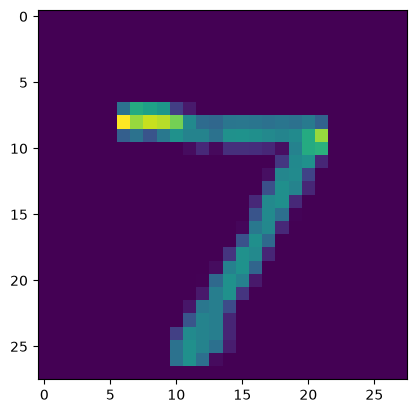

In [19]:
##now the check the first test image and see if the prediction is correct or not
plt.imshow(X_test[0],)  

In [21]:
prediction = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step


In [27]:
## check the another image and see if the prediction is correct or not
print(np.argmax(prediction[128]))

8


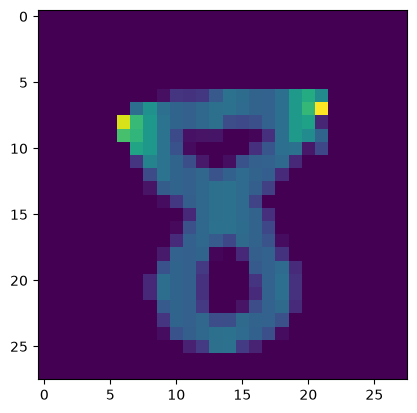

In [28]:
plt.imshow(X_test[128])

In [46]:
import os
print(os.listdir())

['main.py', 'model.h5', 'notebook.ipynb', 'requirements.txt']


In [48]:
model.save("model.keras")